# Поиск аномалий: LOF и Isolation Forest

## Учебное задание (часть под руководством преподавателя)

**Данные:** `data/diy.txt` — агрегированные показатели по клиентам.

| Столбец | Смысл |
|---|---|
| `ClientID` | идентификатор клиента |
| `Recency` | давность последнего визита, дней |
| `Frequency` | число визитов (**Частота**) |
| `Monetary_Q` | количество приобретённого, шт. |
| `Monetary_A` | сумма покупок, руб. (**Сумма**) |

**Условия задания:**

1. использовать только показатели **Частота** (`Frequency`) и **Сумма** (`Monetary_A`);
2. рассматривать только клиентов с **Частота > 1**;
3. найти аномалии алгоритмами **LOF** и **Isolation Forest** (библиотека `scikit-learn`) и сравнить их результаты.

**План работы:** загрузка данных → подготовка (фильтр + масштабирование) → LOF → Isolation Forest →
сравнение результатов → проверка роли условия «Частота > 1» → выводы.

## 1. Импорт библиотек и настройки

In [1]:
import os

# кэш matplotlib держим в папке проекта, чтобы не зависеть от прав в профиле пользователя
os.environ.setdefault("MPLCONFIGDIR", ".mplconfig")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
import sklearn

%matplotlib inline
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

DATA_DIR = Path("data") if Path("data").exists() else Path(".")
print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__, "| pandas:", pd.__version__, "| matplotlib:", matplotlib.__version__)
print("Файлы данных:", [p.name for p in sorted(DATA_DIR.glob("*.txt"))])

scikit-learn: 1.9.1
numpy: 2.5.5 | pandas: 3.1.1 | matplotlib: 3.11.2
Файлы данных: ['banks.txt', 'diy.txt']


## 2. Загрузка данных

In [2]:
diy = pd.read_csv(DATA_DIR / "diy.txt")

print("Размер таблицы:", diy.shape)
display(diy.head())

print("\nТипы столбцов:")
print(diy.dtypes.to_string())
print("\nПропуски:", int(diy.isna().sum().sum()))
display(diy[["Recency", "Frequency", "Monetary_Q", "Monetary_A"]].describe().round(1))

Размер таблицы: (42746, 5)


,ClientID,Recency,Frequency,Monetary_Q,Monetary_A
0,client13166,682,2,23,2705
1,client1239,35,43,219,42161
2,client30041,190,25,133,16057
3,client36276,289,4,12,4614
4,client14136,217,6,36,35870



Типы столбцов:
ClientID        str
Recency       int64
Frequency     int64
Monetary_Q    int64
Monetary_A    int64

Пропуски: 0


,Recency,Frequency,Monetary_Q,Monetary_A
count,42746.0,42746.0,42746.0,42746.0
mean,205.5,6.2,52.4,14705.7
std,205.0,9.1,102.4,32645.5
min,1.0,1.0,1.0,10.0
25%,39.0,1.0,7.0,2301.2
50%,130.0,3.0,21.0,6410.0
75%,333.0,7.0,58.0,16234.8
max,791.0,174.0,5457.0,3887309.0


В таблице **42 746 клиентов**. Распределения сильно асимметричны:
медианная частота — 3 визита, максимальная — 174; медианная сумма — 6 410 руб., максимальная — 3,89 млн руб.
Именно поэтому аномалии нужно искать не «по среднему», а методами, учитывающими локальную плотность.

## 3. Подготовка выборки: только Частота и Сумма, Частота > 1

* **Частота** (`Frequency`) — сколько раз клиент совершал визиты;
* **Сумма** (`Monetary_A`) — на какую сумму (в рублях) он купил.

`Monetary_Q` (количество штук) и `Recency` (давность визита) по условию задания **не используем**.

Условие **Частота > 1** убирает клиентов, приходивших ровно один раз: таких в файле около 30 %,
и все они образуют один большой «плоский» слой, который забивает поиск аномалий.
Что произойдёт без этого фильтра, мы отдельно проверим в разделе 8.

In [3]:
FEATURES = ["Frequency", "Monetary_A"]

mask = diy["Frequency"] > 1
X_raw = diy.loc[mask, FEATURES].reset_index(drop=True)

print(f"Клиентов всего:              {len(diy)}")
print(f"Клиентов с Частота > 1:      {len(X_raw)}  ({len(X_raw) / len(diy):.1%})")
print(f"Отброшено (Частота = 1):     {len(diy) - len(X_raw)}")
display(X_raw.describe().round(1))

Клиентов всего:              42746
Клиентов с Частота > 1:      29887  (69.9%)
Отброшено (Частота = 1):     12859


,Frequency,Monetary_A
count,29887.0,29887.0
mean,8.4,19511.7
std,10.0,37893.2
min,2.0,45.0
25%,3.0,4454.0
50%,5.0,10169.0
75%,10.0,22437.0
max,174.0,3887309.0


## 4. Масштабирование признаков

Оба алгоритма работают с расстояниями (LOF — напрямую, Isolation Forest — через случайные разрезы по осям),
а у нас признаки в разных единицах: визиты — единицы, сумма — сотни тысяч рублей.
Без масштабирования сумма «задавит» частоту. Приводим оба признака к виду $z = (x - \bar{x}) / \sigma$.

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

X_scaled = pd.DataFrame(X, columns=["Frequency_z", "Monetary_A_z"])
display(X_scaled.describe().round(2))

,Frequency_z,Monetary_A_z
count,29887.00,29887.00
mean,0.00,0.00
std,1.00,1.00
min,-0.64,-0.51
25%,-0.54,-0.40
50%,-0.34,-0.25
75%,0.16,0.08
max,16.49,102.07


## 5. LOF — Local Outlier Factor (настройки по умолчанию)

**Идея.** Для каждой точки LOF сравнивает плотность её окружения с плотностью окружения её $k$ соседей.
Плотность оценивается через *достижимое расстояние* (reachability distance), а итоговая величина —
это среднее отношение локальной плотности соседей к собственной локальной плотности:

$$LOF_k(x) = \frac{1}{k}\sum_{o \in N_k(x)} \frac{lrd_k(o)}{lrd_k(x)}$$

* $LOF \approx 1$ — точка в «своём» регионе, обычный объект;
* $LOF \gg 1$ — точка лежит в разрежённом регионе, хотя её соседи плотные, т.е. **аномалия**.

Важное свойство метода: он **локальный**, поэтому находит не только «больших», но и «странных» клиентов
(например, много визитов при маленькой сумме), которые не выделяются глобально.

**Параметры по умолчанию в sklearn:** `n_neighbors=20`, `contamination='auto'`.
При `contamination='auto'` внутренний порог `offset_ = -1.5`, и точка считается аномалией,
если $LOF > 1.5$ (в `scikit-learn` это соответствует `negative_outlier_factor_ < -1.5`).

In [5]:
lof = LocalOutlierFactor()   # novelty=False, n_neighbors=20, contamination='auto' — всё по умолчанию
lof_labels = lof.fit_predict(X)
lof_score = -lof.negative_outlier_factor_     # само значение LOF; > 1.5 -> аномалия

print("Параметры модели:", f"n_neighbors={lof.n_neighbors}, contamination={lof.contamination}, novelty={lof.novelty}")
print(f"Внутренний порог offset_ = {lof.offset_}  ->  аномалия при LOF > {-lof.offset_}")

n_lof = int((lof_labels == -1).sum())
print(f"\nНайдено аномалий: {n_lof} из {len(lof_labels)}  ({n_lof / len(lof_labels):.2%})")

diy_lof = X_raw.assign(LOF=lof_score.round(3), label=lof_labels)
print("\nТоп-10 аномалий по значению LOF:")
display(diy_lof.sort_values("LOF", ascending=False).head(10).reset_index(drop=True))

print("Аномалии (label=-1) и нормальные клиенты (label=1):")
display(diy_lof.groupby("label")[FEATURES + ["LOF"]].agg(["mean", "median", "min", "max"]).round(1))

Параметры модели: n_neighbors=20, contamination=auto, novelty=False
Внутренний порог offset_ = -1.5  ->  аномалия при LOF > 1.5

Найдено аномалий: 75 из 29887  (0.25%)

Топ-10 аномалий по значению LOF:


,Frequency,Monetary_A,LOF,label
0,107,3887309,21.273,-1
1,174,1443255,6.126,-1
2,17,986618,5.130,-1
3,8,862,3.180,-1
4,173,124840,2.576,-1
5,23,636101,2.442,-1
6,11,1987,2.397,-1
7,154,114298,2.279,-1
8,16,2160,2.202,-1
9,12,1967,2.074,-1


Аномалии (label=-1) и нормальные клиенты (label=1):


Frequency                 Monetary_A                         LOF                  
           mean median min  max       mean   median  min      max mean median  min   max
label                                                                                   
-1         37.9   13.0   3  174   155729.3   2764.0  357  3887309  2.1    1.7  1.5  21.3
 1          8.3    5.0   2  119    19169.0  10181.0   45   431752  1.0    1.0  0.9   1.5

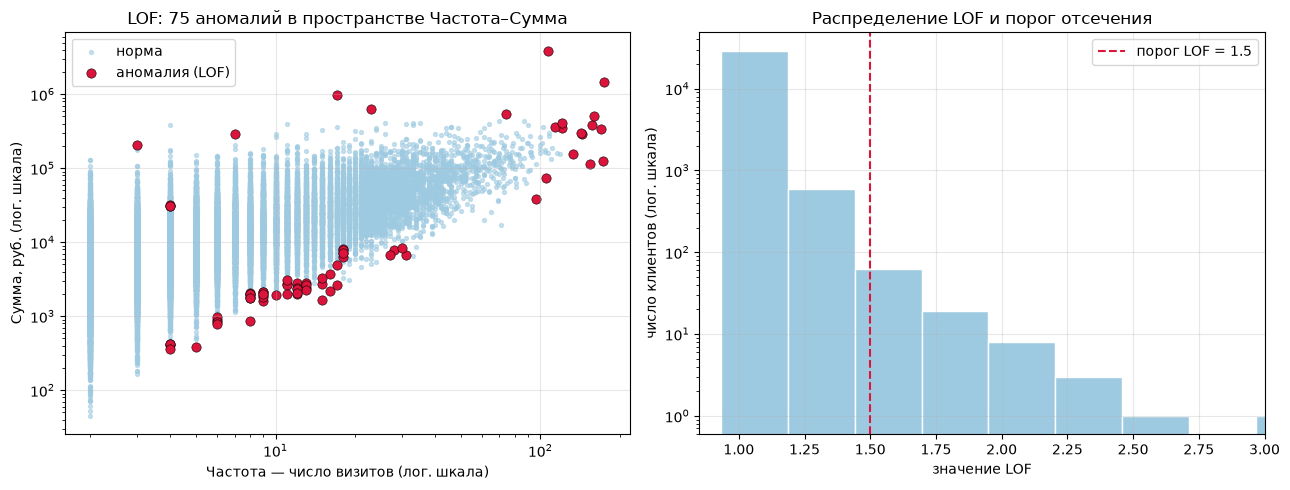

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
normal = diy_lof["label"] == 1
ax.scatter(diy_lof.loc[normal, "Frequency"], diy_lof.loc[normal, "Monetary_A"],
           s=8, color="#9ecae1", alpha=0.55, label="норма")
ax.scatter(diy_lof.loc[~normal, "Frequency"], diy_lof.loc[~normal, "Monetary_A"],
           s=45, color="crimson", edgecolor="black", linewidth=0.4, label="аномалия (LOF)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Частота — число визитов (лог. шкала)")
ax.set_ylabel("Сумма, руб. (лог. шкала)")
ax.set_title(f"LOF: {n_lof} аномалий в пространстве Частота–Сумма")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.hist(lof_score, bins=80, color="#9ecae1", edgecolor="white")
ax.axvline(-lof.offset_, color="crimson", linestyle="--", label=f"порог LOF = {-lof.offset_}")
ax.set_yscale("log")
ax.set_xlim(0.85, 3.0)
ax.set_xlabel("значение LOF")
ax.set_ylabel("число клиентов (лог. шкала)")
ax.set_title("Распределение LOF и порог отсечения")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Что видно.** Аномалий 75 (0,25 %). Это клиенты двух типов:

* «сверхактивные»: 107 визитов и 3,89 млн руб., 174 визита и 1,44 млн руб. — они далеко от основной массы;
* «несогласованные»: например, 8 визитов при сумме 862 руб. или 17 визитов при 986 тыс. руб. —
  для своего региона такие сочетания частоты и суммы нетипичны, и LOF это чувствует.

При этом медианная сумма у аномалий (2 764 руб.) *ниже*, чем у остальных (10 181 руб.):
аномалия — не обязательно «самый большой», это «самый непохожий на соседей».

## 6. Isolation Forest

**Идея.** Строится ансамбль случайных деревьев: в каждом узле случайно выбирается признак и случайный порог,
точка делится до тех пор, пока не окажется в отдельном листе. Аномалию **легче изолировать** — путь до неё короче.

$$s(x, n) = 2^{-\frac{E[h(x)]}{c(n)}}$$

где $h(x)$ — длина пути до листа, $c(n)$ — средняя длина пути в дереве на $n$ объектах.
$s \to 1$ — аномалия, $s \approx 0.5$ — норма.

**Параметры по умолчанию:** `n_estimators=100`, `max_samples='auto'` (= 256 при большом $n$), `contamination='auto'`.
При `contamination='auto'` порог `offset_ = -0.5`: аномалией считается точка, у которой
`score_samples` ниже $-0.5$. Доля таких точек **не задаётся** и зависит от данных.

In [7]:
iso = IsolationForest(random_state=42)      # остальные параметры — по умолчанию
if_labels = iso.fit_predict(X)
if_score = -iso.score_samples(X)              # чем больше, тем «аномальнее»

print("Параметры модели:", {k: iso.get_params()[k] for k in ["n_estimators", "max_samples", "contamination"]})
print(f"Внутренний порог offset_ = {iso.offset_}")

n_if = int((if_labels == -1).sum())
print(f"\nНайдено аномалий: {n_if} из {len(if_labels)}  ({n_if / len(if_labels):.2%})")

diy_if = X_raw.assign(IF=if_score.round(4), label=if_labels)
print("\nТоп-10 аномалий по Isolation Forest:")
display(diy_if.sort_values("IF", ascending=False).head(10).reset_index(drop=True))

Параметры модели: {'n_estimators': 100, 'max_samples': 'auto', 'contamination': 'auto'}
Внутренний порог offset_ = -0.5

Найдено аномалий: 4413 из 29887  (14.77%)

Топ-10 аномалий по Isolation Forest:


,Frequency,Monetary_A,IF,label
0,107,3887309,0.8467,-1
1,157,386355,0.8461,-1
2,174,1443255,0.8461,-1
3,159,502515,0.8461,-1
4,121,407138,0.8461,-1
5,119,429072,0.8455,-1
6,169,343301,0.8450,-1
7,121,345280,0.8438,-1
8,114,359973,0.8432,-1
9,142,297086,0.8421,-1


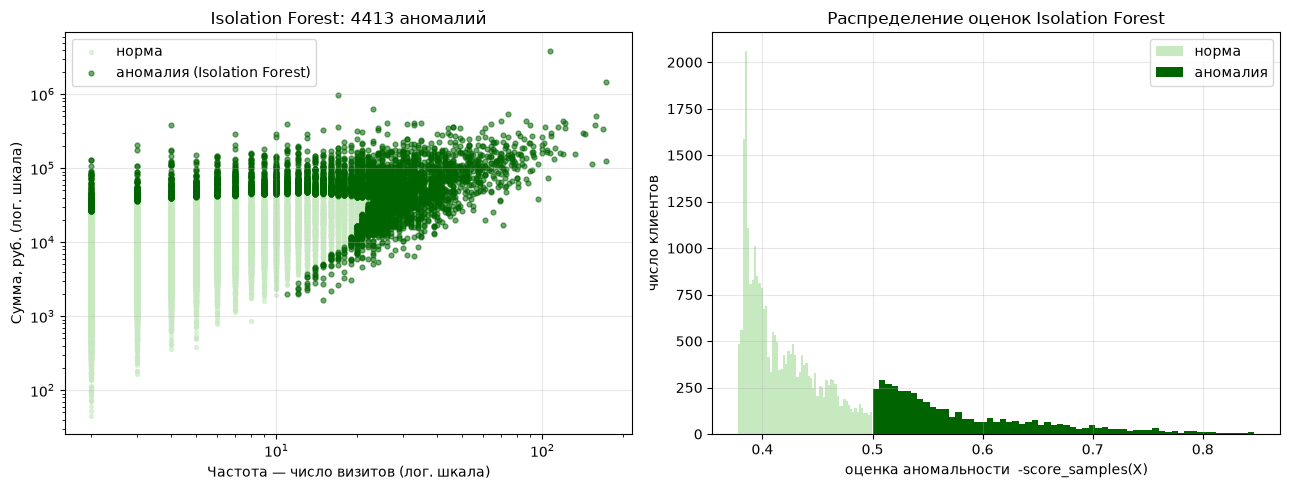

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
normal = diy_if["label"] == 1
ax.scatter(diy_if.loc[normal, "Frequency"], diy_if.loc[normal, "Monetary_A"],
           s=8, color="#c7e9c0", alpha=0.55, label="норма")
ax.scatter(diy_if.loc[~normal, "Frequency"], diy_if.loc[~normal, "Monetary_A"],
           s=12, color="darkgreen", alpha=0.55, label="аномалия (Isolation Forest)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Частота — число визитов (лог. шкала)")
ax.set_ylabel("Сумма, руб. (лог. шкала)")
ax.set_title(f"Isolation Forest: {n_if} аномалий")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.hist(if_score[if_labels == 1], bins=60, color="#c7e9c0", label="норма")
ax.hist(if_score[if_labels == -1], bins=60, color="darkgreen", label="аномалия")
ax.set_xlabel("оценка аномальности  -score_samples(X)")
ax.set_ylabel("число клиентов")
ax.set_title("Распределение оценок Isolation Forest")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Сравнение LOF и Isolation Forest

Алгоритмы отвечают на разные вопросы:

* **LOF** — «насколько плотность вокруг точки ниже, чем у её соседей» (локальная геометрия);
* **Isolation Forest** — «насколько быстро точку можно отрезать случайными разрезами» (глобальная разреженность).

Кроме того, при `contamination='auto'` у них **разные пороги**: $LOF > 1.5$ против $s < -0.5$.
Поэтому «в лоб» сравнивать количества нельзя — сравним в двух постановках:
(1) как есть, с порогами по умолчанию; (2) при одинаковой доле аномалий (одинаковом `contamination`).

In [9]:
lof_an = lof_labels == -1
if_an = if_labels == -1

inter = int((lof_an & if_an).sum())
union = int((lof_an | if_an).sum())

print("Сравнение при настройках по умолчанию")
print(f"  LOF:               {n_lof}  ({n_lof / len(X):.2%})")
print(f"  Isolation Forest:  {n_if}  ({n_if / len(X):.2%})")
print(f"  Пересечение:       {inter}")
print(f"  Только LOF:        {n_lof - inter}")
print(f"  Только IF:         {n_if - inter}")
print(f"  Jaccard(LOF, IF):  {inter / union:.4f}")

display(pd.crosstab(pd.Series(lof_labels, name="LOF"),
                    pd.Series(if_labels, name="Isolation Forest")))

Сравнение при настройках по умолчанию
  LOF:               75  (0.25%)
  Isolation Forest:  4413  (14.77%)
  Пересечение:       46
  Только LOF:        29
  Только IF:         4367
  Jaccard(LOF, IF):  0.0104


Isolation Forest,-1,1
LOF,,
-1,46,29
1,4367,25445


Isolation Forest с contamination=0.00251  ->  75 аномалий
Пересечение с LOF: 13 из 75
Доля пойманных LOF-аномалий: 17.3%


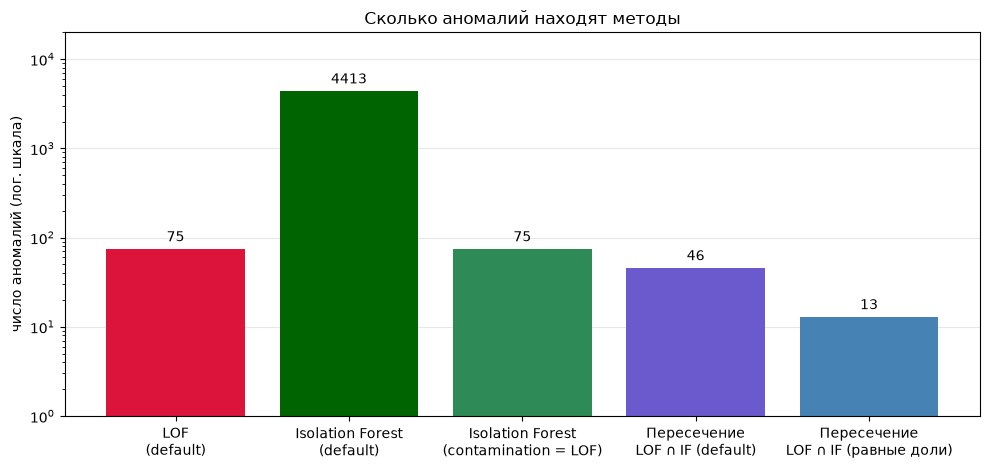

In [10]:
# Вариант 2: одинаковое ожидаемое число аномалий — contamination задаём равной доле, найденной LOF
iso_same = IsolationForest(contamination=n_lof / len(X), random_state=42)
iso_same_labels = iso_same.fit_predict(X)
iso_same_an = iso_same_labels == -1

print(f"Isolation Forest с contamination={n_lof / len(X):.5f}  ->  {int(iso_same_an.sum())} аномалий")
print(f"Пересечение с LOF: {int((iso_same_an & lof_an).sum())} из {n_lof}")
print(f"Доля пойманных LOF-аномалий: {(iso_same_an & lof_an).sum() / n_lof:.1%}")

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar(["LOF\n(default)", "Isolation Forest\n(default)", "Isolation Forest\n(contamination = LOF)",
               "Пересечение\nLOF ∩ IF (default)", "Пересечение\nLOF ∩ IF (равные доли)"],
              [n_lof, n_if, int(iso_same_an.sum()), inter, int((iso_same_an & lof_an).sum())],
              color=["crimson", "darkgreen", "seagreen", "slateblue", "steelblue"])
ax.bar_label(bars, padding=3)
ax.set_yscale("log")
ax.set_ylim(1, 20000)
ax.set_ylabel("число аномалий (лог. шкала)")
ax.set_title("Сколько аномалий находят методы")
ax.grid(axis="y", alpha=0.3, which="major")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Вывод по сравнению.** При настройках по умолчанию LOF выделяет 75 клиентов (0,25 %),
а Isolation Forest — 4 413 (14,8 %): у последнего порог `-0.5` при `contamination='auto'`
отсекает слишком много точек. Пересечение — 46 объектов, Jaccard всего 0,01, т.е. **это разные определения
аномальности**. Если задать Isolation Forest ту же долю аномалий, что нашёл LOF, он выделит 75 точек,
из которых совпадут с LOF только 13: ядро («сверхбольшие» клиенты) общее, а периферия у методов разная.

Практический вывод: результаты LOF и Isolation Forest нужно рассматривать как **два ранжирования**
и смотреть на пересечение/согласие, а не на «число аномалий» при пороге по умолчанию.

## 8. Проверка: зачем условие «Частота > 1»

Запустим LOF на тех же двух признаках, но **без** фильтра — на всех 42 746 клиентах.

In [11]:
X_all = diy[FEATURES].reset_index(drop=True)
X_all_scaled = StandardScaler().fit_transform(X_all)
lof_all_labels = LocalOutlierFactor().fit_predict(X_all_scaled)

an = lof_all_labels == -1
print(f"Клиентов:            {len(diy)}")
print(f"Аномалий без фильтра: {an.sum()}  ({an.mean():.2%})")
print(f"Из них с Частота = 1: {(diy.loc[an, 'Frequency'] == 1).sum()}  "
      f"({(diy.loc[an, 'Frequency'] == 1).mean():.1%} всех аномалий)")
print("\nРаспределение частоты среди найденных аномалий (топ-5 значений):")
print(diy.loc[an, "Frequency"].value_counts().head(5).to_string())

Клиентов:            42746
Аномалий без фильтра: 1346  (3.15%)
Из них с Частота = 1: 1272  (94.5% всех аномалий)

Распределение частоты среди найденных аномалий (топ-5 значений):
Frequency
1     1272
8        7
4        7
9        6
18       5


Без фильтра LOF находит 1 346 аномалий, и **94,5 % из них — клиенты с Частота = 1**.
Причина: у таких клиентов частота постоянна (всего одно значение), а сумма меняется на несколько порядков,
поэтому локальная плотность в их полосе низкая. Метод добросовестно помечает их как аномалии,
но для бизнеса это не аномалии, а просто «новички». Условие **Частота > 1** убирает этот эффект,
и остаётся 75 содержательных аномалий.

## 9. Итоги и ответы на задание

| Что сделано | Результат |
|---|---|
| Отбор признаков | `Frequency` (Частота) и `Monetary_A` (Сумма) |
| Условие «Частота > 1» | 29 887 клиентов вместо 42 746 |
| Подготовка | стандартизация `StandardScaler` (у признаков разный масштаб) |
| LOF, настройки по умолчанию | **75 аномалий (0,25 %)**, порог $LOF > 1.5$ |
| Isolation Forest, настройки по умолчанию | **4 413 аномалий (14,8 %)**, порог $s < -0.5$ |
| Пересечение LOF ∩ Isolation Forest | 46 объектов (Jaccard ≈ 0,01) |
| Isolation Forest с той же долей аномалий | 75 объектов, из них 13 совпали с LOF |
| Без фильтра «Частота > 1» | 1 346 «аномалий», из них 94,5 % — однократные клиенты |

**Что важно запомнить:**

1. LOF и Isolation Forest — разные модели аномальности; одинаковые данные и «настройки по умолчанию»
   дают разные по смыслу и по количеству результаты.
2. `contamination='auto'` — это не «ожидаемая доля 1 %», а конкретный порог; при `auto` у LOF он
   достаточно консервативный (1,5), у Isolation Forest — мягкий ($-0.5$), поэтому он «ловит» 15 % данных.
3. Аномалия не означает «самое большое значение»: LOF помечает и «мелких, но непохожих» клиентов;
   поэтому результат нужно смотреть содержательно (сумма + частота вместе), а не только по модулю оценки.
4. Подготовка данных (фильтр по частоте, масштабирование) меняет результат сильнее, чем выбор алгоритма.